# Wettervergleich: Berlin

Dieses Notebook vergleicht die täglichen Wetterwerte vom **13. bis 26. Oktober 2025**. Es stellt Open-Meteo-Daten für einen Punkt im Berliner Zentrum den Messungen der DWD-Station **Berlin-Tempelhof (00433)** gegenüber.

Verglichen werden Tagesmitteltemperatur und Niederschlag. Beide Datenquellen werden für dieselben 14 Kalendertage abgefragt. Für den Abruf ist eine Internetverbindung erforderlich; ein API-Schlüssel ist nicht nötig.

## 1. Vergleichszeitraum festlegen

Untersucht werden der 13. bis einschließlich 26. Oktober 2025. Beide Quellen werden auf genau diesen Zeitraum begrenzt, damit nur dieselben Tage miteinander verglichen werden.

In [6]:
from datetime import date

startdatum = date(2025, 10, 13)
enddatum = date(2025, 10, 26)

print(f"Vergleichszeitraum: {startdatum:%d.%m.%Y} bis {enddatum:%d.%m.%Y}")

Vergleichszeitraum: 13.10.2025 bis 26.10.2025


## 2. Wetterdaten abrufen

Open-Meteo liefert Tageswerte für einen Koordinatenpunkt im Berliner Zentrum. Die DWD-Tageswerte stammen von der Station Berlin-Tempelhof (00433). Der Code lädt beide Archive, ordnet die Werte nach Datum zu und behält nur den gewünschten 14-Tage-Zeitraum.

In [12]:
import csv
import io
import json
import time
from urllib.error import URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen
from zipfile import ZipFile

parameter = {
    "latitude": 52.52,
    "longitude": 13.405,
    "start_date": startdatum.isoformat(),
    "end_date": enddatum.isoformat(),
    "daily": "temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum",
    "timezone": "Europe/Berlin",
}
open_meteo_url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parameter)
with urlopen(open_meteo_url, timeout=30) as antwort:
    wetter = json.load(antwort)
open_meteo = wetter["daily"]

dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/historical/"
    "tageswerte_KL_00433_19480101_20251231_hist.zip"
)
dwd_inhalt = None
for versuch in range(3):
    try:
        dwd_request = Request(dwd_url, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(dwd_request, timeout=90) as antwort:
            dwd_inhalt = antwort.read()
        break
    except (OSError, URLError):
        if versuch == 2:
            raise
        time.sleep(2)

dwd_zip = ZipFile(io.BytesIO(dwd_inhalt))
produkt_datei = next(
    name for name in dwd_zip.namelist()
    if name.startswith("produkt_klima_tag_") and name.endswith("_00433.txt")
)
dwd_tageswerte = {}

with dwd_zip.open(produkt_datei) as datei:
    reader = csv.DictReader(io.TextIOWrapper(datei, encoding="latin-1"), delimiter=";")
    for rohe_zeile in reader:
        zeile = {
            schluessel.strip(): (wert or "").strip()
            for schluessel, wert in rohe_zeile.items()
            if schluessel
        }
        messdatum = zeile["MESS_DATUM"]
        if not messdatum.startswith("2025"):
            continue

        datum = f"{messdatum[:4]}-{messdatum[4:6]}-{messdatum[6:8]}"
        if not startdatum.isoformat() <= datum <= enddatum.isoformat():
            continue

        def dwd_wert(spalte):
            rohwert = zeile.get(spalte, "")
            if not rohwert:
                return None
            wert = float(rohwert)
            return None if wert == -999 else wert

        dwd_tageswerte[datum] = {
            "temperature_mean": dwd_wert("TMK"),
            "temperature_min": dwd_wert("TNK"),
            "temperature_max": dwd_wert("TXK"),
            "precipitation": dwd_wert("RSK"),
        }

dwd_zip.close()
print(f"Open-Meteo: {len(open_meteo['time'])} Tage")
print(f"DWD Berlin-Tempelhof (Station 00433): {len(dwd_tageswerte)} Tage")
del antwort, datum, datei, dwd_inhalt, dwd_request, dwd_url, dwd_zip
del messdatum, open_meteo_url, parameter, produkt_datei, reader, rohe_zeile
del versuch, wetter, zeile, dwd_wert

Open-Meteo: 14 Tage
DWD Berlin-Tempelhof (Station 00433): 14 Tage


## 3. Quellen im Diagramm vergleichen

Oben werden die Tagesmitteltemperaturen als Linien verglichen; unten stehen die Niederschlagsmengen als gruppierte Balken. Orange steht für Open-Meteo am Berliner Zentrum, Türkis für die DWD-Station Berlin-Tempelhof.

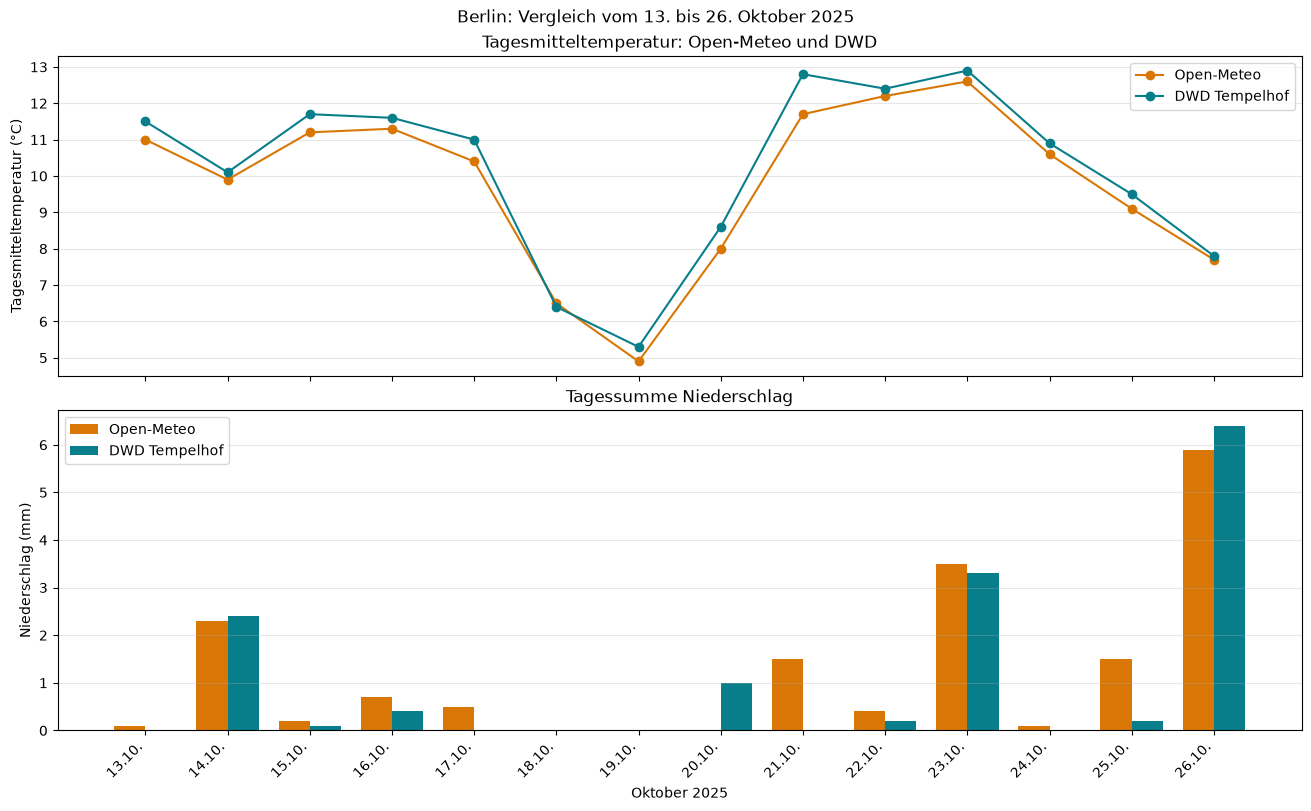

In [13]:
import matplotlib.pyplot as plt

open_meteo_index = {
    datum: index for index, datum in enumerate(open_meteo["time"])
}
vergleichstage = [datum for datum in open_meteo["time"] if datum in dwd_tageswerte]
positionen = list(range(len(vergleichstage)))
datumslabels = [f"{datum[8:10]}.{datum[5:7]}." for datum in vergleichstage]

open_meteo_temperatur = [
    open_meteo["temperature_2m_mean"][open_meteo_index[datum]]
    for datum in vergleichstage
]
dwd_temperatur = [
    dwd_tageswerte[datum]["temperature_mean"] for datum in vergleichstage
]
open_meteo_regen = [
    open_meteo["precipitation_sum"][open_meteo_index[datum]]
    for datum in vergleichstage
]
dwd_regen = [
    dwd_tageswerte[datum]["precipitation"] for datum in vergleichstage
]

fig, (temperatur_ax, regen_ax) = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True,
    layout="constrained",
)

farben = {"Open-Meteo": "#d97706", "DWD Tempelhof": "#087e8b"}
temperatur_ax.plot(
    positionen,
    open_meteo_temperatur,
    marker="o",
    color=farben["Open-Meteo"],
    label="Open-Meteo",
)
temperatur_ax.plot(
    positionen,
    dwd_temperatur,
    marker="o",
    color=farben["DWD Tempelhof"],
    label="DWD Tempelhof",
)
temperatur_ax.set_ylabel("Tagesmitteltemperatur (°C)")
temperatur_ax.set_title("Tagesmitteltemperatur: Open-Meteo und DWD")
temperatur_ax.grid(axis="y", alpha=0.3)
temperatur_ax.legend()

balkenbreite = 0.38
regen_ax.bar(
    [position - balkenbreite / 2 for position in positionen],
    [wert if wert is not None else float("nan") for wert in open_meteo_regen],
    width=balkenbreite,
    color=farben["Open-Meteo"],
    label="Open-Meteo",
)
regen_ax.bar(
    [position + balkenbreite / 2 for position in positionen],
    [wert if wert is not None else float("nan") for wert in dwd_regen],
    width=balkenbreite,
    color=farben["DWD Tempelhof"],
    label="DWD Tempelhof",
)
regen_ax.set_ylabel("Niederschlag (mm)")
regen_ax.set_title("Tagessumme Niederschlag")
regen_ax.legend()
regen_ax.grid(axis="y", alpha=0.3)
regen_ax.set_xticks(positionen, datumslabels, rotation=45, ha="right")
regen_ax.set_xlabel("Oktober 2025")

fig.suptitle("Berlin: Vergleich vom 13. bis 26. Oktober 2025")
plt.show()
plt.close(fig)
del balkenbreite, datumslabels, farben, fig, open_meteo_index, positionen, regen_ax, temperatur_ax

## 4. Unterschiede zusammenfassen

Die Auswertung berechnet für die gemeinsamen Tage die mittlere Tagesmitteltemperatur und die Niederschlagssumme je Quelle. Zusätzlich zeigt sie die Differenz als **DWD minus Open-Meteo** an. Fehlende Messwerte werden dabei ausgelassen.

In [14]:
open_meteo_temperatur_gueltig = [
    wert for wert in open_meteo_temperatur if wert is not None
]
dwd_temperatur_gueltig = [wert for wert in dwd_temperatur if wert is not None]
open_meteo_regen_gueltig = [wert for wert in open_meteo_regen if wert is not None]
dwd_regen_gueltig = [wert for wert in dwd_regen if wert is not None]

print(f"Gemeinsam verglichene Tage: {len(vergleichstage)}")
if open_meteo_temperatur_gueltig and dwd_temperatur_gueltig:
    open_meteo_mittel = sum(open_meteo_temperatur_gueltig) / len(open_meteo_temperatur_gueltig)
    dwd_mittel = sum(dwd_temperatur_gueltig) / len(dwd_temperatur_gueltig)
    print(f"Mittlere Temperatur Open-Meteo: {open_meteo_mittel:.2f} °C")
    print(f"Mittlere Temperatur DWD: {dwd_mittel:.2f} °C")
    print(f"Differenz DWD minus Open-Meteo: {dwd_mittel - open_meteo_mittel:+.2f} °C")

if open_meteo_regen_gueltig and dwd_regen_gueltig:
    open_meteo_summe = sum(open_meteo_regen_gueltig)
    dwd_summe = sum(dwd_regen_gueltig)
    print(f"Niederschlag Open-Meteo: {open_meteo_summe:.1f} mm")
    print(f"Niederschlag DWD: {dwd_summe:.1f} mm")
    print(f"Differenz DWD minus Open-Meteo: {dwd_summe - open_meteo_summe:+.1f} mm")

del open_meteo_temperatur_gueltig, dwd_temperatur_gueltig, open_meteo_regen_gueltig, dwd_regen_gueltig

Gemeinsam verglichene Tage: 14
Mittlere Temperatur Open-Meteo: 9.79 °C
Mittlere Temperatur DWD: 10.18 °C
Differenz DWD minus Open-Meteo: +0.39 °C
Niederschlag Open-Meteo: 16.7 mm
Niederschlag DWD: 14.0 mm
Differenz DWD minus Open-Meteo: -2.7 mm


## Einordnung

Open-Meteo verwendet hier einen Koordinatenpunkt im Berliner Zentrum, während DWD an der Station Berlin-Tempelhof misst. Unterschiede sind daher erwartbar und bedeuten nicht automatisch, dass eine Quelle fehlerhaft ist. Verglichen werden Tageswerte desselben Zeitraums, aber nicht Messungen exakt am selben Ort.

### Übung

Ändere Start- und Enddatum in der ersten Codezelle und führe danach alle Zellen erneut aus. Achte darauf, einen Zeitraum zu wählen, für den sowohl Open-Meteo- als auch DWD-Daten vorliegen.